# Tipo de cambio nominal real brasileño
**Tomás Agustín Yáñez Meneses**

Código: F072.CLP.BRL.N.O.D

Variable: BRL/CLP -> esto representa una variable flotante sobre el tipo de cambio nominal del real brasileño al peso chileno, es decir, cuantos pesos chilenos cuesta un real

Esta es una serie de tiempo que refleja el tipo de cambio nominal del real brasileño a peso chileno a través de los años.

## Importación de Bibliotecas



In [400]:
# Primero se importan las bibliotecas necesarias para trabajar con este dataset, en el reporte asignado se trabajó con Pandas, NumPy y Matplotlib.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Carga del archivo

In [401]:
df = pd.read_csv('Real(in).csv')

## Exploración de los datos

In [402]:
# Ahora se revisan las primeras cinco observaciones utilizando head()
df.head()

,Fecha,Valor
0,1996-01-02,418.72
1,1996-01-03,417.25
2,1996-01-04,416.25
3,1996-01-05,419.02
4,1996-01-06,NaN


In [403]:
#Se revisan los nombres de las columnas

df.columns

Index(['Fecha', 'Valor'], dtype='object')

In [404]:
#Cantidad de filas y columnas del dataset

df.shape

(11193, 2)

In [405]:
#Tipos de datos
df.dtypes

,0
Fecha,object
Valor,float64


In [406]:
#Comprobacion de valores faltantes
df.isnull().sum()

,0
Fecha,0
Valor,3556


## Preparación de la serie

In [407]:
#Se identica la columna que tiene la fecha
df['Fecha']

,Fecha
0,1996-01-02
1,1996-01-03
2,1996-01-04
3,1996-01-05
4,1996-01-06
...,...
11188,2026-08-20
11189,2026-08-21
11190,2026-08-22
11191,2026-08-23


In [408]:
#Se convierte la columna de tipo objeto a formato fecha
df['Fecha']= pd.to_datetime(df['Fecha'])
df['Fecha']

,Fecha
0,1996-01-02
1,1996-01-03
2,1996-01-04
3,1996-01-05
4,1996-01-06
...,...
11188,2026-08-20
11189,2026-08-21
11190,2026-08-22
11191,2026-08-23


In [409]:
#Ahora se ordenan los datos cronologicamente
df.sort_values(by='Fecha')

,Fecha,Valor
0,1996-01-02,418.72
1,1996-01-03,417.25
2,1996-01-04,416.25
3,1996-01-05,419.02
4,1996-01-06,NaN
...,...,...
11188,2026-08-20,178.01
11189,2026-08-21,177.80
11190,2026-08-22,NaN
11191,2026-08-23,NaN


In [410]:
#Se identifica la columna con los valores
df['Valor']

,Valor
0,418.72
1,417.25
2,416.25
3,419.02
4,NaN
...,...
11188,178.01
11189,177.80
11190,NaN
11191,NaN


In [411]:
df.isnull().sum()

,0
Fecha,0
Valor,3556


Dado que el numero de observaciones es alto, y los valores faltantes corresponden alrededor del 31% de la muestra, además como estamos trabajando con una serie de tiempo, reemplazaré los valores faltantes utilizando una media movil de frecuencia de 7 observaciones.

In [412]:
#Se calucla la media movil
media_movil = df['Valor'].rolling(window=7, min_periods=1).mean()

In [413]:
#Se reemplazan los valores faltantes
df['Valor'].fillna(media_movil, inplace=True)

In [414]:
#Se verifica que no hayan valores nulos
df.isnull().sum()

,0
Fecha,0
Valor,0


# Elaboracion del gráfico

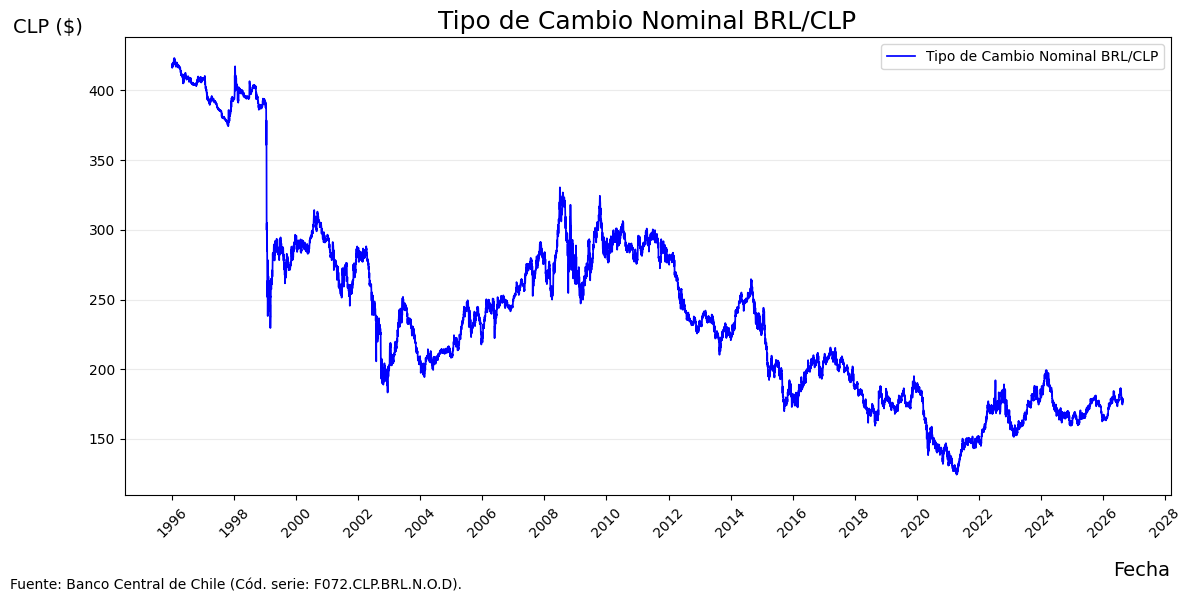

In [415]:
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(df['Fecha'], df['Valor'],
        color='blue', linewidth=1.25, label='Tipo de Cambio Nominal BRL/CLP')
ax.set_title('Tipo de Cambio Nominal BRL/CLP', fontsize=18)
ax.set_xlabel('Fecha', fontsize=14, loc='right', labelpad=15)
ax.set_ylabel('CLP ($)', fontsize=14, rotation=0, loc='top')
ax.grid(axis='y', alpha=.25)
ax.legend(loc='upper right') # Add legend

# Set major ticks to show every 2 years
ax.xaxis.set_major_locator(mdates.YearLocator(2))
# Format major ticks to display the year
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.xticks(rotation=45)
# Add source text
plt.figtext(0.01, 0.01, 'Fuente: Banco Central de Chile (Cód. serie: F072.CLP.BRL.N.O.D).', horizontalalignment='left', fontsize=10, color='black')
plt.tight_layout()
plt.show()

# Interpretación

**¿Cuál es la tendencia de la serie?**

Observando como ha variado históricamente el tipo de cambio nominal, se presenta una tendencia bajista de la serie, sin embargo, observando los últimos 10 años, se puede observar que se ha mantenido alrededor de los 150 a 200 pesos por real.


**¿Se observan aumentos o disminuciones importantes?**

Sí, en el año 1999 se puede observar una fuerte depreciación del tipo cambio nominal, donde se oberva una caída de casi 200 pesos por real, así como en los siguientes años:


*   2001-2002
*   2008-2009
*   2014-2016
*   2020-2021

Así como también se observan aumentos importantes en los años:

*   2002-2003
*   2009-2010

**Existen periodos con valores especialmente altos o bajos?**

En el año 1996 se registró el valor más alto alcanzando casi los 420 pesos por real, en el año 1999 se registró un valor alrededor de los 225 pesos por real.
Luego se observa que en el periodo alcanzó un valor que alcanza entre 300-350 pesos por real, para luego comenzar a bajar a su monto mínimo registrado en el año 2020 debajo de los 150 pesos por real.

**Se aprecia algún patrón, fluctuación o cambio relevante?**

Desde el año 2013 hasta el 2020 se ha observado una tendencia bajista, lo que lleva a interpretar un deterioro macroeconómico en Brasil, aunque en el escenario actual se mantiene con oscilaciones entre 150-200 pesos por real, pero sin recuperar el nivel alcanzado con los años 2000.